Name:  RAJDEEP BAROR

Roll No.:  25BEC090
### Algorithm Analysis 

### Setup

In [ ]:
import sys
import platform
import time
import random
import math
import statistics
import matplotlib.pyplot as plt

random.seed(42)

print("python version:", sys.version.split()[0])
print("platform:", platform.platform())
print("metric used: median of repeated trials")

def measure_median(fn, trials=5):
    times = []
    for i in range(trials):
        t0 = time.perf_counter()
        fn()
        t1 = time.perf_counter()
        times.append(t1 - t0)
    return statistics.median(times)

python version: 3.11.2
platform: Linux-6.12.105+-x86_64-with-glibc2.36
metric used: median of repeated trials


### Lab Work 1: Implementing Representative Algorithms

In [ ]:
def get_index(arr, idx):
    return arr[idx]

def bin_search(arr, target):
    lo = 0
    hi = len(arr) - 1
    while lo <= hi:
        mid = (lo + hi) // 2
        if arr[mid] == target:
            return mid
        elif arr[mid] < target:
            lo = mid + 1
        else:
            hi = mid - 1
    return -1

def lin_search(arr, target):
    for i in range(len(arr)):
        if arr[i] == target:
            return i
    return -1

def merge_sort(arr):
    if len(arr) <= 1:
        return arr
    mid = len(arr) // 2
    left = merge_sort(arr[:mid])
    right = merge_sort(arr[mid:])
    res = []
    i = 0
    j = 0
    while i < len(left) and j < len(right):
        if left[i] <= right[j]:
            res.append(left[i])
            i += 1
        else:
            res.append(right[j])
            j += 1
    res.extend(left[i:])
    res.extend(right[j:])
    return res

def pair_count(arr):
    cnt = 0
    n = len(arr)
    for i in range(n):
        for j in range(i + 1, n):
            if arr[i] < arr[j]:
                cnt += 1
    return cnt

def subsets(arr):
    if len(arr) == 0:
        return [[]]
    rest = subsets(arr[1:])
    ans = []
    for s in rest:
        ans.append(s)
        ans.append([arr[0]] + s)
    return ans

### Lab Work 1: Benchmarking Growth Rates and Normalized Ratios

In [ ]:
# input sizes chosen safely per growth class
sizes_fast = [1000, 5000, 10000, 25000, 50000]
sizes_nlogn = [500, 1000, 2000, 4000, 8000]
sizes_quad = [100, 250, 500, 750, 1000]
sizes_exp = [8, 10, 12, 14, 16]

t_const, t_log, t_lin = [], [], []
for n in sizes_fast:
    arr = list(range(n))
    t_const.append(measure_median(lambda: get_index(arr, n // 2), trials=7))
    t_log.append(measure_median(lambda: bin_search(arr, -1), trials=7))
    t_lin.append(measure_median(lambda: lin_search(arr, -1), trials=5))

t_nlogn = []
for n in sizes_nlogn:
    arr = [random.randint(0, 10000) for i in range(n)]
    t_nlogn.append(measure_median(lambda: merge_sort(arr), trials=3))

t_quad = []
for n in sizes_quad:
    arr = [random.randint(0, 1000) for i in range(n)]
    t_quad.append(measure_median(lambda: pair_count(arr), trials=3))

t_exp = []
for n in sizes_exp:
    arr = list(range(n))
    t_exp.append(measure_median(lambda: subsets(arr), trials=3))

print("linear search T(n)/n:")
for i in range(len(sizes_fast)):
    print("n =", sizes_fast[i], "t =", round(t_lin[i], 6), "t/n =", round(t_lin[i] / sizes_fast[i], 9))

print("\nmerge sort T(n)/(n log2 n):")
for i in range(len(sizes_nlogn)):
    n = sizes_nlogn[i]
    print("n =", n, "t =", round(t_nlogn[i], 6), "ratio =", round(t_nlogn[i] / (n * math.log2(n)), 8))

print("\npair count T(n)/n^2:")
for i in range(len(sizes_quad)):
    n = sizes_quad[i]
    print("n =", n, "t =", round(t_quad[i], 6), "t/n^2 =", round(t_quad[i] / (n * n), 9))

linear search T(n)/n:
n = 1000 t = 1.9e-05 t/n = 1.9e-08
n = 5000 t = 9.3e-05 t/n = 1.9e-08
n = 10000 t = 0.000185 t/n = 1.9e-08
n = 25000 t = 0.000473 t/n = 1.9e-08
n = 50000 t = 0.000944 t/n = 1.9e-08

merge sort T(n)/(n log2 n):
n = 500 t = 0.000494 ratio = 1.1e-07
n = 1000 t = 0.001046 ratio = 1e-07
n = 2000 t = 0.002232 ratio = 1e-07
n = 4000 t = 0.004769 ratio = 1e-07
n = 8000 t = 0.010358 ratio = 1e-07

pair count T(n)/n^2:
n = 100 t = 0.000153 t/n^2 = 1.5e-08
n = 250 t = 0.000911 t/n^2 = 1.5e-08
n = 500 t = 0.003911 t/n^2 = 1.6e-08
n = 750 t = 0.008954 t/n^2 = 1.6e-08
n = 1000 t = 0.01613 t/n^2 = 1.6e-08


### Lab Work 1: Plotting Execution Time vs Input Size

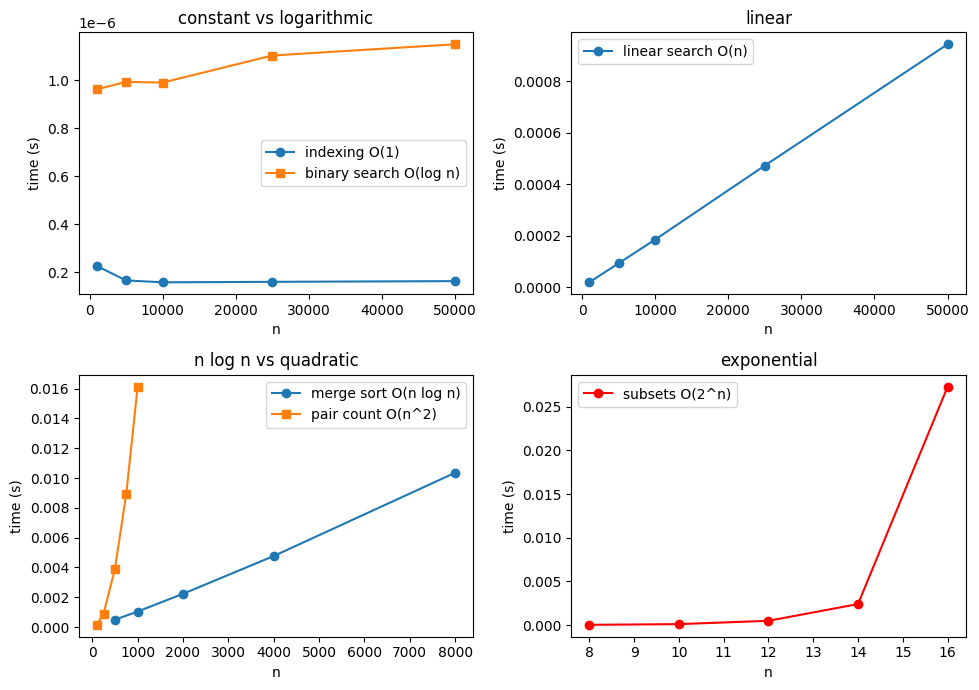

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

axes[0, 0].plot(sizes_fast, t_const, marker="o", label="indexing O(1)")
axes[0, 0].plot(sizes_fast, t_log, marker="s", label="binary search O(log n)")
axes[0, 0].set_title("constant vs logarithmic")
axes[0, 0].set_xlabel("n")
axes[0, 0].set_ylabel("time (s)")
axes[0, 0].legend()

axes[0, 1].plot(sizes_fast, t_lin, marker="o", label="linear search O(n)")
axes[0, 1].set_title("linear")
axes[0, 1].set_xlabel("n")
axes[0, 1].set_ylabel("time (s)")
axes[0, 1].legend()

axes[1, 0].plot(sizes_nlogn, t_nlogn, marker="o", label="merge sort O(n log n)")
axes[1, 0].plot(sizes_quad, t_quad, marker="s", label="pair count O(n^2)")
axes[1, 0].set_title("n log n vs quadratic")
axes[1, 0].set_xlabel("n")
axes[1, 0].set_ylabel("time (s)")
axes[1, 0].legend()

axes[1, 1].plot(sizes_exp, t_exp, marker="o", color="red", label="subsets O(2^n)")
axes[1, 1].set_title("exponential")
axes[1, 1].set_xlabel("n")
axes[1, 1].set_ylabel("time (s)")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

### Lab Work 2: Prefix Averages Implementations and Validation

In [ ]:
def prefix_average1(s):
    n = len(s)
    a = [0] * n
    for j in range(n):
        total = 0
        for i in range(j + 1):
            total += s[i]
        a[j] = total / (j + 1)
    return a

def prefix_average2(s):
    n = len(s)
    a = [0] * n
    total = 0
    for j in range(n):
        total += s[j]
        a[j] = total / (j + 1)
    return a

# validation on empty, singleton, positive, negative, mixed
tests = [
    [],
    [7],
    [2, 4, 6, 8],
    [-5, -10, -15],
    [10, -4, 7, -3, 0]
]

for t in tests:
    r1 = prefix_average1(t)
    r2 = prefix_average2(t)
    print("input:", t, "-> match:", r1 == r2, "out:", r2)

input: [] -> match: True out: []
input: [7] -> match: True out: [7.0]
input: [2, 4, 6, 8] -> match: True out: [2.0, 3.0, 4.0, 5.0]
input: [-5, -10, -15] -> match: True out: [-5.0, -7.5, -10.0]
input: [10, -4, 7, -3, 0] -> match: True out: [10.0, 3.0, 4.333333333333333, 2.5, 2.0]


### Lab Work 2: Benchmarking and Plotting Quadratic vs Linear Prefix Averages

n | prefix_average1 (s) | prefix_average2 (s)
200 | 0.000408 | 1e-05
500 | 0.002462 | 2.6e-05
1000 | 0.010065 | 5.2e-05
1500 | 0.022961 | 7.9e-05
2000 | 0.041446 | 0.000107
3000 | 0.094625 | 0.000161


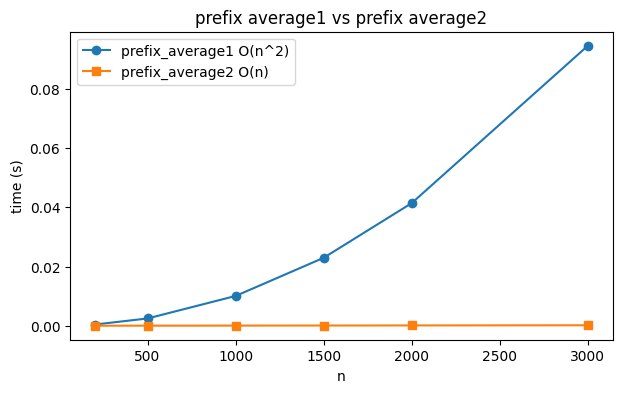

In [ ]:
ns = [200, 500, 1000, 1500, 2000, 3000]
times1 = []
times2 = []

for n in ns:
    seq = [random.uniform(-100, 100) for i in range(n)]
    times1.append(measure_median(lambda: prefix_average1(seq), trials=3))
    times2.append(measure_median(lambda: prefix_average2(seq), trials=5))

print("n | prefix_average1 (s) | prefix_average2 (s)")
for i in range(len(ns)):
    print(ns[i], "|", round(times1[i], 6), "|", round(times2[i], 6))

plt.figure(figsize=(7, 4))
plt.plot(ns, times1, marker="o", label="prefix_average1 O(n^2)")
plt.plot(ns, times2, marker="s", label="prefix_average2 O(n)")
plt.title("prefix average1 vs prefix average2")
plt.xlabel("n")
plt.ylabel("time (s)")
plt.legend()
plt.show()